# Training Snapshots — PyTorch Prediction Interval Neural Network (Blob + Inverted Bounds)

This notebook generates the heteroscedastic **blob** dataset via `src.data`, initializes `PiNeuralNetwork` with **inverted bounds** (`ub_bias_init = -1.0`, `lb_bias_init = +1.0`) and `confidence = 0.9`, trains it while collecting **50 snapshots**, and visualizes how the bounds untangle and converge in a **5-column x 10-row** grid.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from src.data.dataset_generators import DatasetGenerator
from src.model.lr_schedule import TimeDecreasingLr
from src.model.pi_neural_network import PiNeuralNetwork
from src.plot.training_plots import TrainingSnapshot, plot_training_snapshots_grid

from tqdm import tqdm

In [2]:
# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 1. Generate synthetic blob dataset (inverse-quadratic noise around y=0)
X_MIN, X_MAX = -2.0, 2.0
dataset_gen = DatasetGenerator(
    x_min=X_MIN,
    x_max=X_MAX,
    sample_size=500,
    validation_split=0.2,
    seed=SEED,
)
x_train, y_train, x_val, y_val = dataset_gen.generate_blob()
x_grid = np.linspace(X_MIN, X_MAX, 200)

# 2. Instantiate the PyTorch model with deliberately INVERTED bounds
model = PiNeuralNetwork(
    input_dim=1,
    hidden_layers=[(32, "relu"), (16, "relu")],
    confidence=0.9,
    ub_bias_init=1.0,
    lb_bias_init=-1.0,
    softening_factor=100.0,
    lr=1e-3,
    weight_decay=1e-2,
    alpha=5.0,
    lambda_=0.02,
    mse_inactivity_epochs=50,
    lr_schedule=TimeDecreasingLr(decay=5e-5),
    verbose=False,
)

# 3. Train while collecting 50 snapshots (epoch 0 + 49 steps of 10 epochs = 490 epochs)
N_SNAPSHOTS = 50
EPOCHS_PER_STEP = 30

snapshots: list[TrainingSnapshot] = []
ubs0, lbs0, regr0 = model.predict(x_grid)
snapshots.append(TrainingSnapshot(epoch=0, ubs=ubs0, lbs=lbs0, regr=regr0))
print(f"Initial inverted grid points (epoch 0): {int(np.sum(lbs0 > ubs0))} / {len(x_grid)}")

for _ in tqdm(range(N_SNAPSHOTS - 1)):
    model.fit(x_train, y_train, epochs=EPOCHS_PER_STEP, batch_size=32)
    ubs, lbs, regr = model.predict(x_grid)
    snapshots.append(TrainingSnapshot(epoch=model.epoch, ubs=ubs, lbs=lbs, regr=regr))

# Final validation metrics
val_ubs, val_lbs, val_regr = model.predict(x_val)
covered = (y_val >= val_lbs) & (y_val <= val_ubs)
print(f"Device: {model.device} | Total epochs: {model.epoch}")
print(f"Validation PICP (target 0.90): {np.mean(covered):.3f}")
print(f"Validation MPIW (mean width): {np.mean(val_ubs - val_lbs):.4f}")
print(f"Validation Regression MSE: {np.mean((val_regr - y_val) ** 2):.4f}")
print(f"Final inverted bounds (val): {int(np.sum(val_lbs > val_ubs))}")

Initial inverted grid points (epoch 0): 0 / 200


100%|██████████| 49/49 [01:00<00:00,  1.23s/it]

Device: cuda | Total epochs: 1470
Validation PICP (target 0.90): 0.920
Validation MPIW (mean width): 0.3514
Validation Regression MSE: 0.0328
Final inverted bounds (val): 0


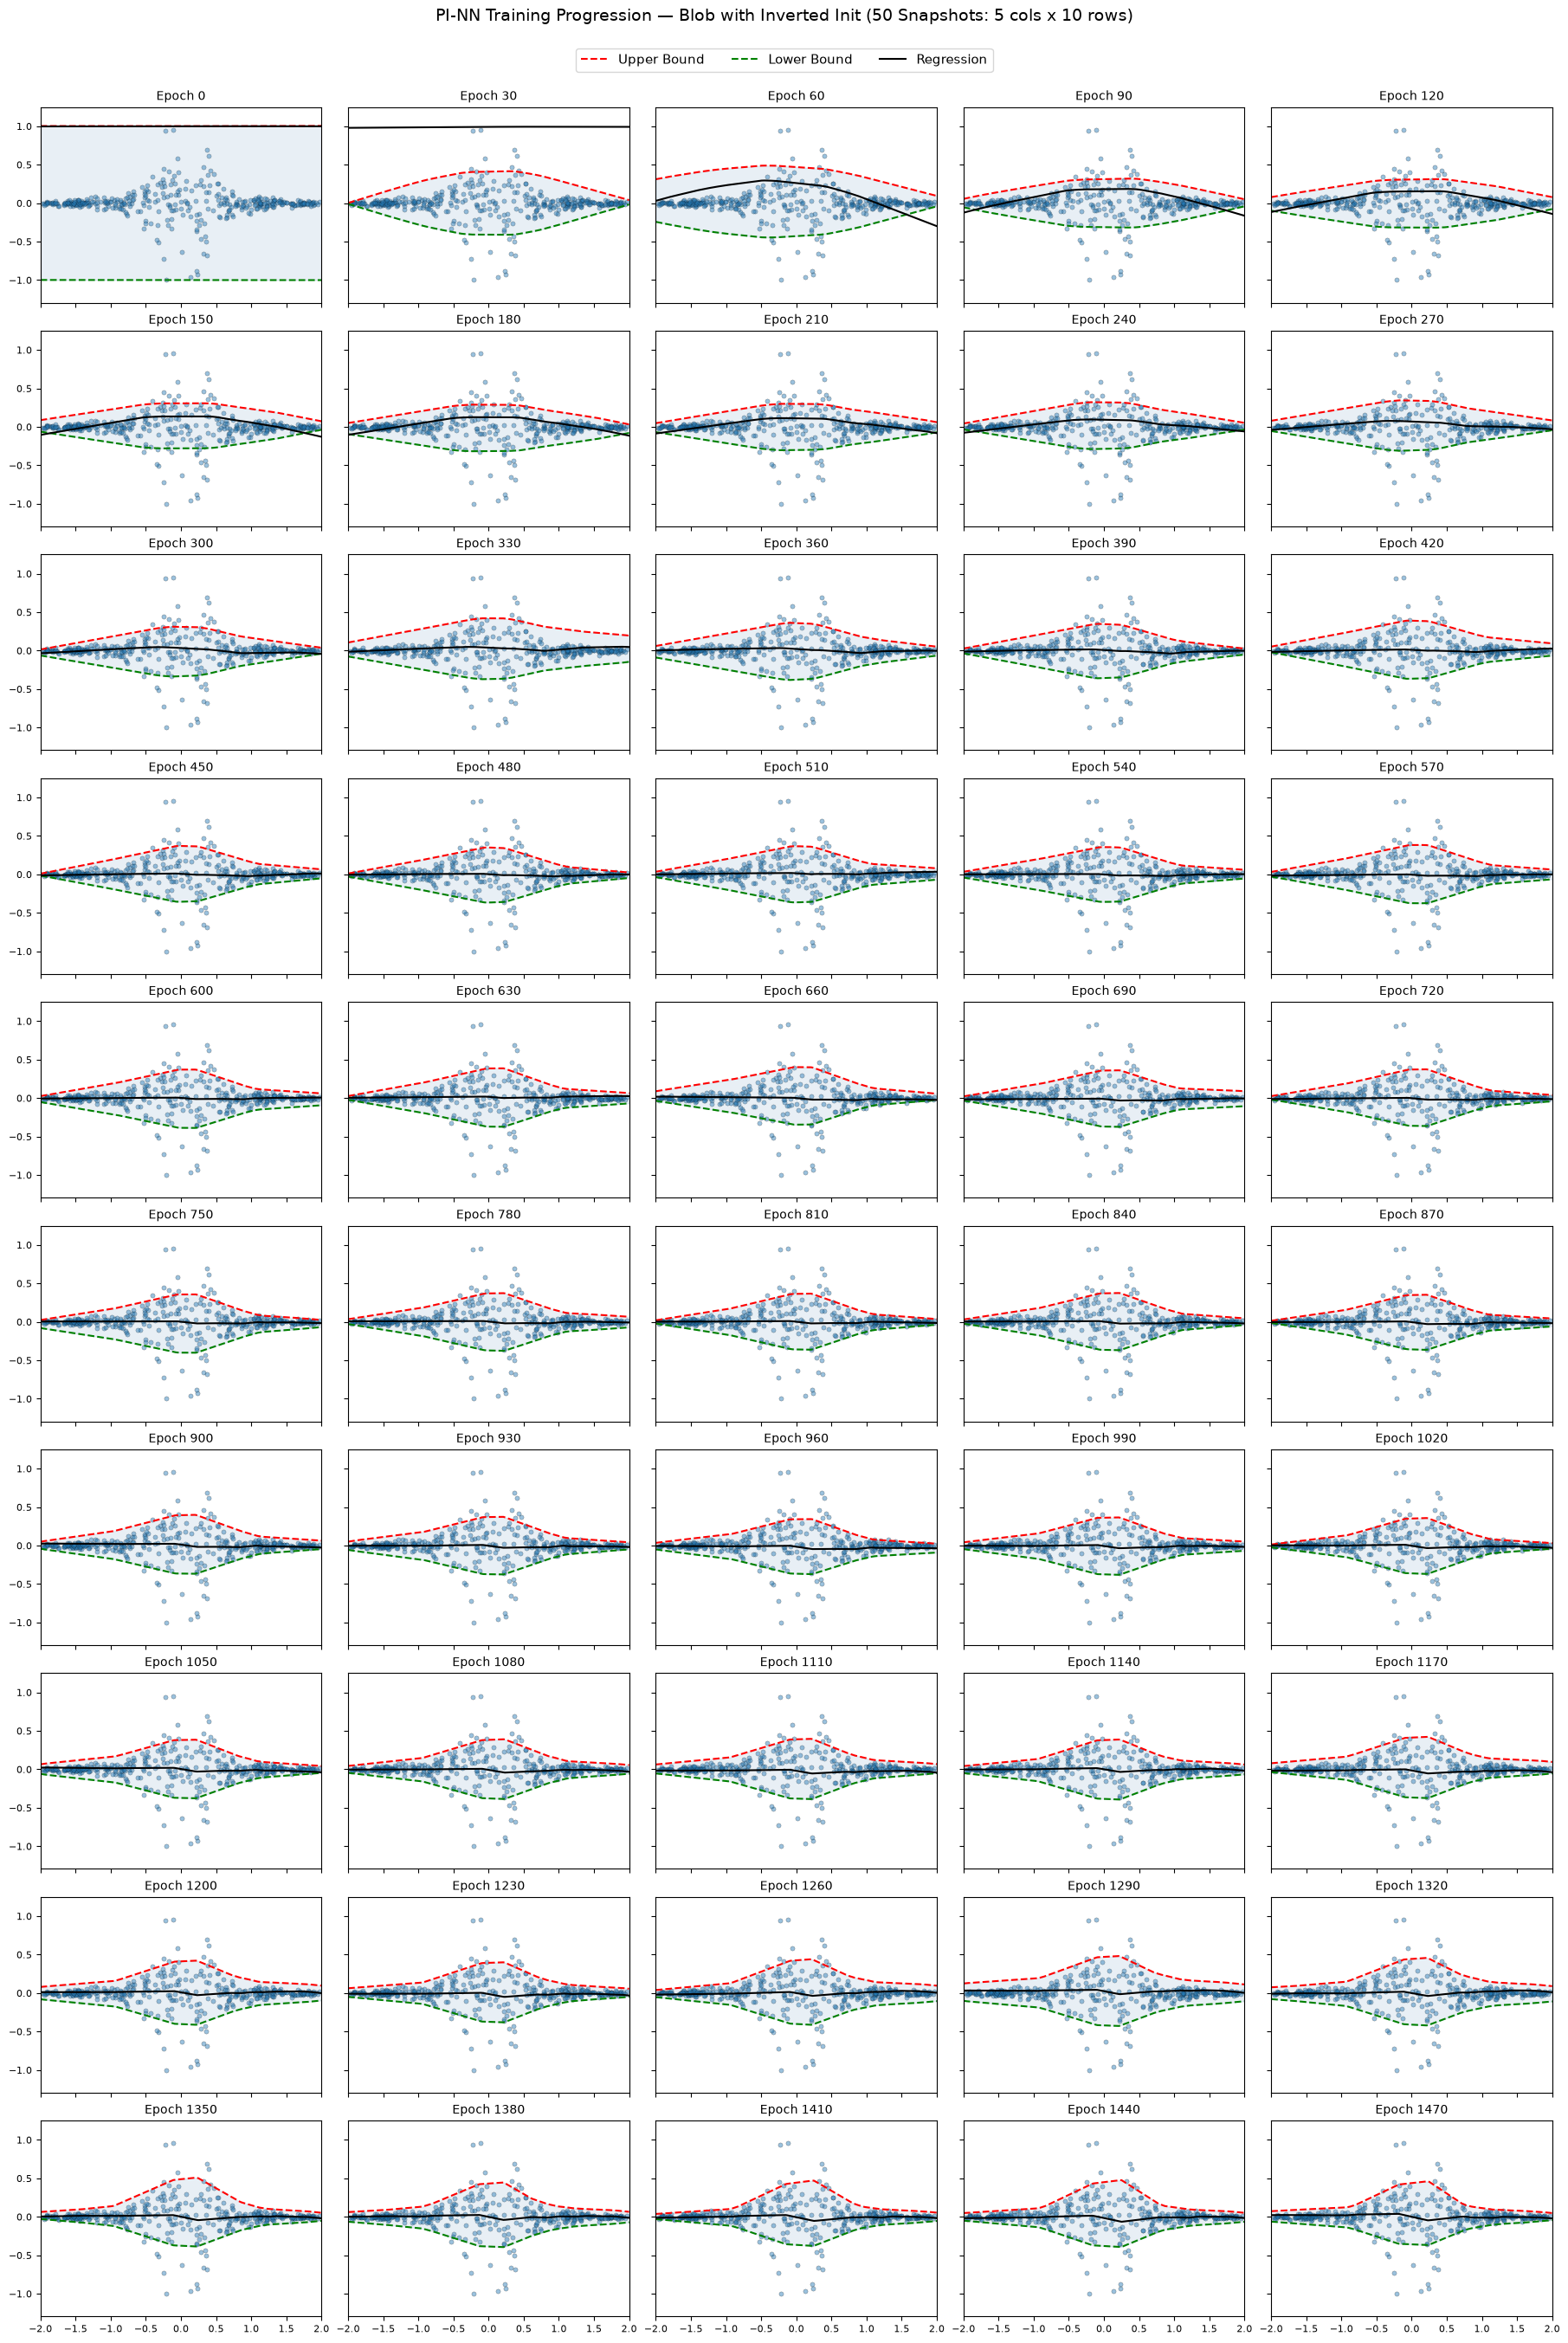

In [3]:
# 4. Plot 5 columns x 10 rows of training progression
y_margin = 0.15 * (y_train.max() - y_train.min())
fig = plot_training_snapshots_grid(
    snapshots=snapshots,
    x=x_train,
    y=y_train,
    x_grid=x_grid,
    ncols=5,
    nrows=10,
    x_lim=(X_MIN, X_MAX),
    y_lim=(float(y_train.min() - y_margin), float(y_train.max() + y_margin)),
    suptitle="PI-NN Training Progression — Blob with Inverted Init (50 Snapshots: 5 cols x 10 rows)",
)
plt.show()